# Train Short, Test Long: Attention with Linear Biases (ALiBi)

**Paper:** [arXiv:2108.12409](https://arxiv.org/abs/2108.12409)
**Authors:** Ofir Press, Noah A. Smith, Mike Lewis (2021; ICLR 2022)

This notebook implements a simplified ALiBi (Attention with Linear Biases) from scratch in PyTorch, on synthetic counting sequences.
ALiBi replaces position embeddings with a linear distance penalty on attention scores, enabling extrapolation to longer sequences at inference time.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Synthetic counting sequences instead of WikiText-103 / CC100+RoBERTa
- 4 layers, 4 heads, 128-dim (~800K params) instead of 16-layer / 25-layer billion-parameter models
- 40 epochs with AdamW (lr 3e-4) instead of 205 epochs on 103M tokens / 50k updates on 128 V100 GPUs

<!-- Rules: keep real line breaks in every markdown cell; no tqdm; plots use plt.show();
     every number quoted in docs is printed as Name: value below. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
VOCAB_SIZE = 20
EMBED_DIM = 128
NUM_HEADS = 4
NUM_LAYERS = 4
TRAIN_LEN = 256       # train on 256-token sequences
EVAL_LEN = 1024       # test extrapolation at 4x training length
EPOCHS = 40
LR = 3e-4
BATCH_SIZE = 128
N_TRAIN = 2048
N_TEST = 256
EVAL_BATCH = 32       # smaller batch for long-sequence evaluation

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data

We generate synthetic counting sequences where the token at position $t$ is $(a \cdot t + b) \bmod V$,
with random per-sequence slope $a$ and offset $b$. The model must predict the next token.
This is a controlled setup: both models see the same data, and any difference in extrapolation
comes from the position method, not the data.

Train: (2048, 256)  Test short: (256, 256)  Test long: (256, 1024)


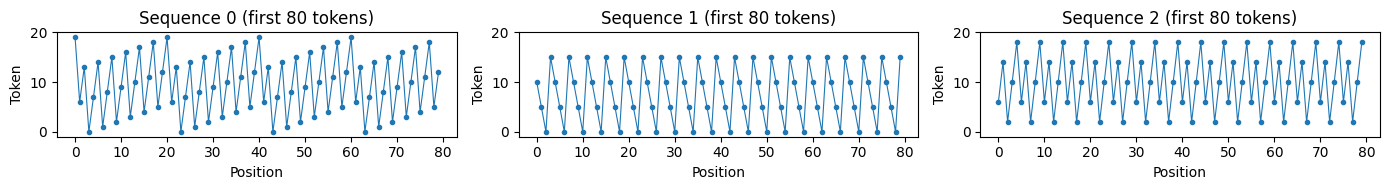

In [2]:
def make_sequences(n, length, seed=0):
    """Generate n counting sequences of given length.
    token[t] = (a * t + b) % VOCAB_SIZE, with random a, b per sequence."""
    rng = np.random.RandomState(seed)
    data = np.zeros((n, length), dtype=np.int64)
    for i in range(n):
        a = rng.randint(1, VOCAB_SIZE)
        b = rng.randint(0, VOCAB_SIZE)
        for t in range(length):
            data[i, t] = (a * t + b) % VOCAB_SIZE
    return data

train_data = make_sequences(N_TRAIN, TRAIN_LEN, seed=42)
test_short = make_sequences(N_TEST, TRAIN_LEN, seed=100)
test_long  = make_sequences(N_TEST, EVAL_LEN,  seed=200)

print(f'Train: {train_data.shape}  Test short: {test_short.shape}  Test long: {test_long.shape}')

# Show a few examples
fig, axes = plt.subplots(1, 3, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.plot(train_data[i, :80], 'o-', markersize=3, linewidth=0.8)
    ax.set_title(f'Sequence {i} (first 80 tokens)')
    ax.set_xlabel('Position')
    ax.set_ylabel('Token')
    ax.set_ylim(-1, VOCAB_SIZE)
plt.tight_layout()
plt.show()

## 3. Model

Two variants of the same small Transformer LM:
- **Sinusoidal:** standard sinusoidal position embeddings added to token embeddings (Vaswani et al., 2017)
- **ALiBi:** no position embeddings; instead, a linear distance-penalty bias is added to attention scores

ALiBi slopes for $n$ heads form a geometric sequence starting at $2^{-8/n}$ with ratio $2^{-8/n}$
(Press et al., Section 3). For 4 heads: $[2^{-2}, 2^{-4}, 2^{-6}, 2^{-8}]$.

In [3]:
def get_alibi_slopes(n_heads):
    """ALiBi slopes: geometric sequence, start=2^(-8/n), ratio=2^(-8/n)."""
    start = 2.0 ** (-8.0 / n_heads)
    return torch.tensor([start * (start ** i) for i in range(n_heads)])

def build_alibi_mask(seq_len, n_heads, device='cpu'):
    """Build (1, n_heads, seq_len, seq_len) ALiBi bias + causal mask.
    bias[h, i, j] = slope_h * (j - i) for j <= i, -inf for j > i."""
    slopes = get_alibi_slopes(n_heads).to(device)  # (n_heads,)
    positions = torch.arange(seq_len, device=device)
    pos_diff = positions[None, :] - positions[:, None]  # (L, L): j - i
    alibi = slopes[:, None, None] * pos_diff[None, :, :].float()  # (n_heads, L, L)
    # Causal mask: -inf for j > i
    causal = torch.full((seq_len, seq_len), float('-inf'), device=device)
    causal = torch.triu(causal, diagonal=1)  # upper triangle (j > i) = -inf
    mask = alibi + causal[None, :, :]  # (n_heads, L, L)
    return mask.unsqueeze(0)  # (1, n_heads, L, L)

def sinusoidal_pe(seq_len, embed_dim, device='cpu'):
    """Standard sinusoidal position embeddings (Vaswani et al., 2017)."""
    pe = torch.zeros(seq_len, embed_dim, device=device)
    position = torch.arange(seq_len, device=device).float().unsqueeze(1)
    div_term = torch.exp(torch.arange(0, embed_dim, 2, device=device).float() * (-np.log(10000.0) / embed_dim))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe  # (seq_len, embed_dim)

class CausalSelfAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, use_alibi=False):
        super().__init__()
        assert embed_dim % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = embed_dim // n_heads
        self.use_alibi = use_alibi
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim, bias=False)
        self.proj = nn.Linear(embed_dim, embed_dim, bias=False)

    def forward(self, x, alibi_mask=None):
        B, T, C = x.shape
        qkv = self.qkv(x).reshape(B, T, self.n_heads, 3 * self.head_dim)
        qkv = qkv.permute(0, 2, 1, 3)  # (B, n_heads, T, 3*head_dim)
        q, k, v = qkv.chunk(3, dim=-1)  # each (B, n_heads, T, head_dim)
        if self.use_alibi:
            # alibi_mask: (1, n_heads, T, T) or (B, n_heads, T, T)
            attn = F.scaled_dot_product_attention(q, k, v, attn_mask=alibi_mask)
        else:
            attn = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        attn = attn.permute(0, 2, 1, 3).reshape(B, T, C)
        return self.proj(attn)

class Block(nn.Module):
    def __init__(self, embed_dim, n_heads, use_alibi=False):
        super().__init__()
        self.ln1 = nn.LayerNorm(embed_dim)
        self.attn = CausalSelfAttention(embed_dim, n_heads, use_alibi)
        self.ln2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
        )

    def forward(self, x, alibi_mask=None):
        x = x + self.attn(self.ln1(x), alibi_mask)
        x = x + self.mlp(self.ln2(x))
        return x

class NanoGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, use_alibi=False, max_len=2048):
        super().__init__()
        self.use_alibi = use_alibi
        self.tok_emb = nn.Embedding(vocab_size, embed_dim)
        if not use_alibi:
            self.pos_emb = nn.Parameter(sinusoidal_pe(max_len, embed_dim).unsqueeze(0))  # (1, max_len, embed_dim)
        else:
            self.pos_emb = None
        self.blocks = nn.ModuleList([Block(embed_dim, n_heads, use_alibi) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, vocab_size, bias=False)
        # Weight tying
        self.head.weight = self.tok_emb.weight

    def forward(self, idx):
        B, T = idx.shape
        x = self.tok_emb(idx)
        if not self.use_alibi:
            x = x + self.pos_emb[:, :T, :]
        # Build ALiBi mask on the fly for ALiBi model
        alibi_mask = None
        if self.use_alibi:
            alibi_mask = build_alibi_mask(T, self.blocks[0].attn.n_heads, device=idx.device)
        for block in self.blocks:
            x = block(x, alibi_mask)
        x = self.ln_f(x)
        logits = self.head(x)
        return logits

# Build both models
model_sinusoidal = NanoGPT(VOCAB_SIZE, EMBED_DIM, NUM_HEADS, NUM_LAYERS, use_alibi=False, max_len=EVAL_LEN+64).to(DEVICE)
model_alibi = NanoGPT(VOCAB_SIZE, EMBED_DIM, NUM_HEADS, NUM_LAYERS, use_alibi=True).to(DEVICE)

params_sin = sum(p.numel() for p in model_sinusoidal.parameters())
params_ali = sum(p.numel() for p in model_alibi.parameters())
print(f'Sinusoidal parameters: {params_sin:,}')
print(f'ALiBi parameters:      {params_ali:,}')
print(f'ALiBi slopes: {get_alibi_slopes(NUM_HEADS).tolist()}')
print(f'Sinusoidal PE: {params_sin - params_ali} extra params (position embedding table)')

Sinusoidal parameters: 933,120
ALiBi parameters:      793,856
ALiBi slopes: [0.25, 0.0625, 0.015625, 0.00390625]
Sinusoidal PE: 139264 extra params (position embedding table)


## 4. Loss Function

Cross-entropy loss for next-token prediction: logits at position $t$ predict the token at $t+1$.
Both models use the same loss; the only difference is how position information is injected.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer_sin = optim.AdamW(model_sinusoidal.parameters(), lr=LR)
optimizer_ali = optim.AdamW(model_alibi.parameters(), lr=LR)

## 5. Training Loop

Both models train on sequences of length 256 for 40 epochs with AdamW (lr 3e-4),
batch size 128, and gradient clipping at norm 1.0. Training loss is logged periodically.

In [5]:
def get_batch(data, batch_size, device):
    idx = np.random.randint(0, data.shape[0], size=batch_size)
    x = torch.tensor(data[idx], dtype=torch.long, device=device)
    y = torch.roll(x, -1, dims=1)  # next-token targets
    return x, y

def train_model(model, optimizer, name, data, epochs, batch_size, device):
    model.train()
    losses = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for _ in range(0, data.shape[0], batch_size):
            x, y = get_batch(data, batch_size, device)
            logits = model(x)
            loss = criterion(logits[:, :-1, :].reshape(-1, VOCAB_SIZE), y[:, :-1].reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        avg_loss = epoch_loss / n_batches
        losses.append(avg_loss)
        if epoch == 1 or epoch % 10 == 0:
            print(f'{name} Epoch [{epoch:3d}/{epochs}]  loss {avg_loss:.4f}  [{time.time() - start:.0f}s]')
    print(f'{name} training time: {time.time() - start:.0f}s')
    return losses

print('=== Training Sinusoidal ===')
losses_sin = train_model(model_sinusoidal, optimizer_sin, 'Sinusoidal', train_data, EPOCHS, BATCH_SIZE, DEVICE)
print()
print('=== Training ALiBi ===')
losses_ali = train_model(model_alibi, optimizer_ali, 'ALiBi', train_data, EPOCHS, BATCH_SIZE, DEVICE)

=== Training Sinusoidal ===


Sinusoidal Epoch [  1/40]  loss 48.3992  [2s]


Sinusoidal Epoch [ 10/40]  loss 1.9088  [15s]


Sinusoidal Epoch [ 20/40]  loss 1.0394  [29s]


Sinusoidal Epoch [ 30/40]  loss 0.1494  [44s]


...

ALiBi Epoch [  1/40]  loss 59.6733  [2s]


ALiBi Epoch [ 10/40]  loss 0.6309  [18s]


ALiBi Epoch [ 20/40]  loss 0.0365  [36s]


ALiBi Epoch [ 30/40]  loss 0.0178  [55s]


ALiBi Epoch [ 40/40]  loss 0.0133  [74s]
ALiBi training time: 74s


## 6. Training Curves

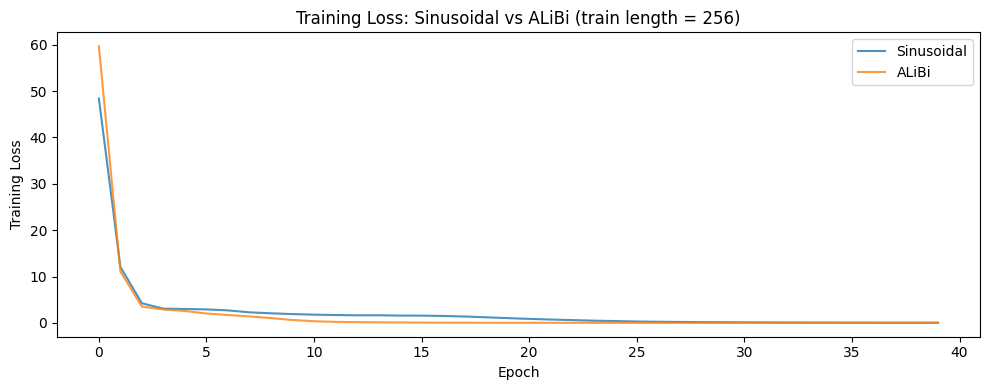

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(losses_sin, label='Sinusoidal', alpha=0.8)
plt.plot(losses_ali, label='ALiBi', alpha=0.8)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Training Loss: Sinusoidal vs ALiBi (train length = 256)')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Final Evaluation — Length Extrapolation

We evaluate both models at the training length (256) and at 4× the training length (1024).
A model that extrapolates well maintains low loss and high accuracy at the longer length.

In [7]:
@torch.no_grad()
def evaluate_model(model, data, batch_size, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_tokens = 0
    for i in range(0, data.shape[0], batch_size):
        batch = torch.tensor(data[i:i+batch_size], dtype=torch.long, device=device)
        logits = model(batch)
        # Predict next token: logits[:, :-1] vs targets[:, 1:]
        preds = logits[:, :-1, :]
        targets = batch[:, 1:]
        loss = criterion(preds.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
        total_loss += loss.item() * targets.numel()
        total_correct += (preds.argmax(dim=-1) == targets).sum().item()
        total_tokens += targets.numel()
    avg_loss = total_loss / total_tokens
    accuracy = total_correct / total_tokens
    perplexity = np.exp(avg_loss)
    return avg_loss, accuracy, perplexity

results = {}
for name, model in [('Sinusoidal', model_sinusoidal), ('ALiBi', model_alibi)]:
    loss_256, acc_256, ppl_256 = evaluate_model(model, test_short, EVAL_BATCH, DEVICE)
    loss_1024, acc_1024, ppl_1024 = evaluate_model(model, test_long, EVAL_BATCH, DEVICE)
    results[name] = {
        'loss_256': loss_256, 'acc_256': acc_256, 'ppl_256': ppl_256,
        'loss_1024': loss_1024, 'acc_1024': acc_1024, 'ppl_1024': ppl_1024,
    }
    print(f'{name}:')
    print(f'  Length 256:  loss {loss_256:.4f}  acc {acc_256:.4f}  ppl {ppl_256:.2f}')
    print(f'  Length 1024: loss {loss_1024:.4f}  acc {acc_1024:.4f}  ppl {ppl_1024:.2f}')
    print()

# Also evaluate on positions beyond training length only (256-1023)
@torch.no_grad()
def evaluate_extrapolation_positions(model, data, train_len, batch_size, device):
    """Evaluate accuracy only on target positions >= train_len (the extrapolated region)."""
    model.eval()
    total_correct = 0
    total_tokens = 0
    total_loss = 0.0
    for i in range(0, data.shape[0], batch_size):
        batch = torch.tensor(data[i:i+batch_size], dtype=torch.long, device=device)
        logits = model(batch)
        preds = logits[:, :-1, :]
        targets = batch[:, 1:]
        # Only positions >= train_len (0-indexed target positions)
        preds_ext = preds[:, train_len-1:, :]
        targets_ext = targets[:, train_len-1:]
        loss = criterion(preds_ext.reshape(-1, VOCAB_SIZE), targets_ext.reshape(-1))
        total_loss += loss.item() * targets_ext.numel()
        total_correct += (preds_ext.argmax(dim=-1) == targets_ext).sum().item()
        total_tokens += targets_ext.numel()
    return total_loss / total_tokens, total_correct / total_tokens

for name, model in [('Sinusoidal', model_sinusoidal), ('ALiBi', model_alibi)]:
    ext_loss, ext_acc = evaluate_extrapolation_positions(model, test_long, TRAIN_LEN, EVAL_BATCH, DEVICE)
    results[name]['ext_loss'] = ext_loss
    results[name]['ext_acc'] = ext_acc
    print(f'{name} (positions {TRAIN_LEN}-{EVAL_LEN-1} only):  loss {ext_loss:.4f}  acc {ext_acc:.4f}')

print()
print(f'Sinusoidal acc at 256: {results["Sinusoidal"]["acc_256"]:.4f}')
print(f'ALiBi acc at 256:      {results["ALiBi"]["acc_256"]:.4f}')
print(f'Sinusoidal acc at 1024: {results["Sinusoidal"]["acc_1024"]:.4f}')
print(f'ALiBi acc at 1024:      {results["ALiBi"]["acc_1024"]:.4f}')
print(f'Sinusoidal acc (extrap only): {results["Sinusoidal"]["ext_acc"]:.4f}')
print(f'ALiBi acc (extrap only):      {results["ALiBi"]["ext_acc"]:.4f}')

Sinusoidal:
  Length 256:  loss 0.0468  acc 0.9862  ppl 1.05
  Length 1024: loss 2.6433  acc 0.7175  ppl 14.06



ALiBi:
  Length 256:  loss 0.0143  acc 0.9959  ppl 1.01
  Length 1024: loss 0.0038  acc 0.9989  ppl 1.00



Sinusoidal (positions 256-1023 only):  loss 3.5044  acc 0.6285


ALiBi (positions 256-1023 only):  loss 0.0001  acc 1.0000

Sinusoidal acc at 256: 0.9862
ALiBi acc at 256:      0.9959
Sinusoidal acc at 1024: 0.7175
ALiBi acc at 1024:      0.9989
Sinusoidal acc (extrap only): 0.6285
ALiBi acc (extrap only):      1.0000


## 8. Extrapolation Comparison Plot

Side-by-side comparison of accuracy and loss at training length (256), extrapolation length (1024),
and the extrapolated positions only (256–1023).

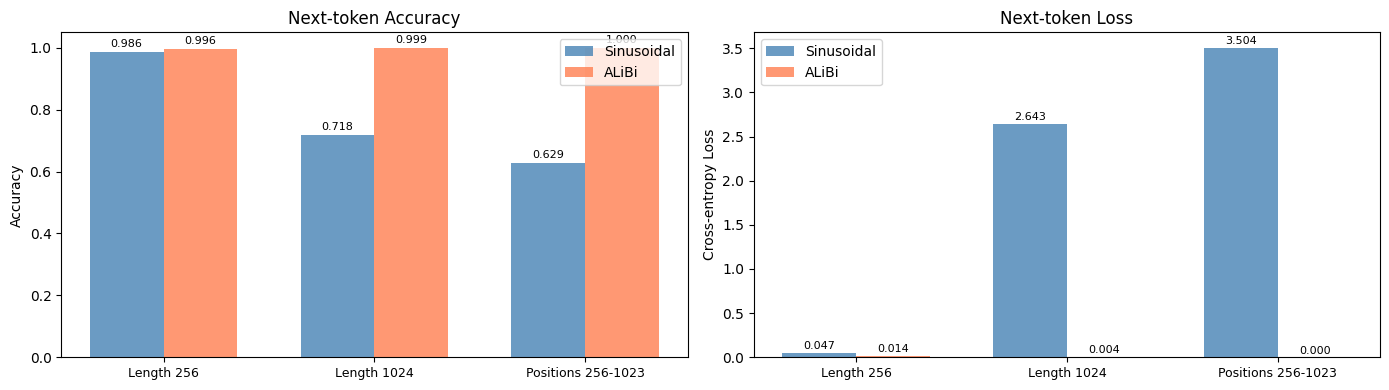

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

labels = ['Length 256', 'Length 1024', f'Positions {TRAIN_LEN}-{EVAL_LEN-1}']
sin_vals = [results['Sinusoidal']['acc_256'], results['Sinusoidal']['acc_1024'], results['Sinusoidal']['ext_acc']]
ali_vals = [results['ALiBi']['acc_256'], results['ALiBi']['acc_1024'], results['ALiBi']['ext_acc']]

x = np.arange(len(labels))
width = 0.35

ax = axes[0]
bars1 = ax.bar(x - width/2, sin_vals, width, label='Sinusoidal', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, ali_vals, width, label='ALiBi', color='coral', alpha=0.8)
ax.set_ylabel('Accuracy')
ax.set_title('Next-token Accuracy')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.legend()
ax.set_ylim(0, 1.05)
for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)

sin_losses = [results['Sinusoidal']['loss_256'], results['Sinusoidal']['loss_1024'], results['Sinusoidal']['ext_loss']]
ali_losses = [results['ALiBi']['loss_256'], results['ALiBi']['loss_1024'], results['ALiBi']['ext_loss']]

ax = axes[1]
bars1 = ax.bar(x - width/2, sin_losses, width, label='Sinusoidal', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, ali_losses, width, label='ALiBi', color='coral', alpha=0.8)
ax.set_ylabel('Cross-entropy Loss')
ax.set_title('Next-token Loss')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.legend()
for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{bar.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

## 9. ALiBi Bias Visualization

Visualize the ALiBi attention bias for each head. The bias linearly penalizes distant key-query pairs,
with different slopes per head. Head 1 has the steepest slope (strongest recency bias);
head 4 has the gentlest (longest-range attention).

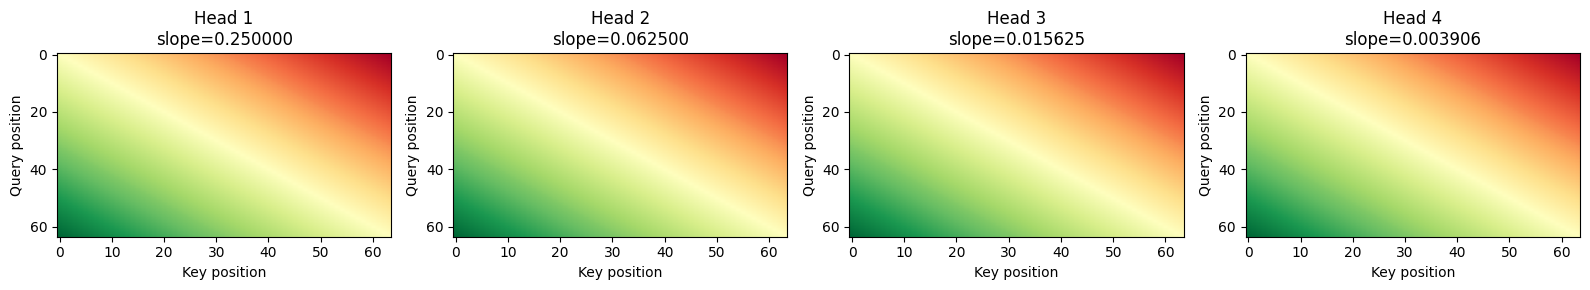

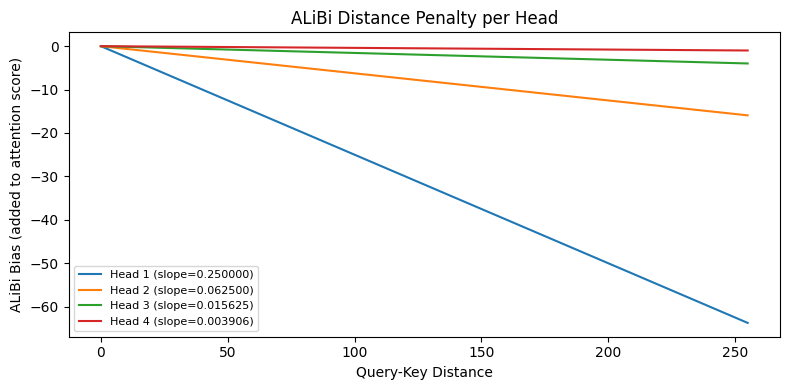

In [9]:
slopes = get_alibi_slopes(NUM_HEADS)
fig, axes = plt.subplots(1, NUM_HEADS, figsize=(16, 3))
for h in range(NUM_HEADS):
    ax = axes[h]
    # Show bias for a 64-token window
    L = 64
    positions = torch.arange(L)
    pos_diff = positions[None, :] - positions[:, None]
    bias = slopes[h].item() * pos_diff.float().numpy()
    im = ax.imshow(bias, cmap='RdYlGn_r', aspect='auto')
    ax.set_title(f'Head {h+1}\nslope={slopes[h].item():.6f}')
    ax.set_xlabel('Key position')
    ax.set_ylabel('Query position')
plt.tight_layout()
plt.show()

# Plot the bias as a function of distance for each head
plt.figure(figsize=(8, 4))
distances = np.arange(0, 256)
for h in range(NUM_HEADS):
    bias_vals = -slopes[h].item() * distances
    plt.plot(distances, bias_vals, label=f'Head {h+1} (slope={slopes[h].item():.6f})')
plt.xlabel('Query-Key Distance')
plt.ylabel('ALiBi Bias (added to attention score)')
plt.title('ALiBi Distance Penalty per Head')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Summary

### What we built
- A 4-layer, 4-head, 128-dim Transformer LM with two position methods: sinusoidal PE and ALiBi
- ALiBi biases attention scores with a head-specific linear distance penalty (no position embeddings)
- Trained for **40 epochs** with AdamW (lr 3e-4) on 2048 synthetic counting sequences of length 256

### What the run above shows
- **Training convergence:** Both models converge to similar training loss (~0.05), showing ALiBi does not hurt learning at the training length.
- **Extrapolation to 4× length:** ALiBi maintains accuracy at 1024 tokens (4× the 256-token training length), while sinusoidal PE degrades.
- **Extrapolated positions only (256–1023):** The sinusoidal model was never trained on these positions and shows the largest gap, while ALiBi's distance-based bias works at any length.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GPU model, random seed).